# DATA 4401 Project 2 - Baseline and Improved Neural Network

This notebook compares a simple feed-forward neural-network baseline against an improved version using feature engineering, regularization, and validation-based early stopping.

**Primary selection metric:** ROC-AUC.  We also report accuracy, precision, recall, and F1 score.  Keep the test set untouched until each final model is evaluated.


## 1. Imports and reproducibility

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


## 2. Load the data

Upload `application_train.csv` to Colab first. If your file has a different name, update the line below.

In [2]:
df = pd.read_csv("application_train.csv")

print("Shape:", df.shape)
display(df.head())
print("\nTarget distribution:")
display(df["TARGET"].value_counts().rename_axis("TARGET").to_frame("count"))
display((df["TARGET"].value_counts(normalize=True) * 100).round(2).rename("percent"))


Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0



Target distribution:


,count
TARGET,
0,282686
1,24825


,percent
TARGET,
0,91.93
1,8.07


## 3. Shared evaluation function

Accuracy alone is not enough here because payment difficulty is the minority class. ROC-AUC is our main comparison metric.

In [3]:
def evaluate_model(y_true, probabilities, threshold=0.50, model_name="Model"):
    predictions = (probabilities >= threshold).astype(int)

    results = {
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0)
    }

    print(pd.Series(results))
    ConfusionMatrixDisplay(confusion_matrix(y_true, predictions)).plot(cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix (threshold = {threshold})")
    plt.show()
    return results


## 4. Baseline model data preparation

This matches the basic approach: use the original application features, median/mode imputation, one-hot encoding, and a stratified split. We make a validation set from the training data so the improved model can use early stopping without looking at the final test set.

In [6]:
y = df["TARGET"].copy()
X_base = df.drop(columns=["TARGET", "SK_ID_CURR"]).copy()

# 20% final test set; the remaining 80% is split into training and validation.
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_base, y, test_size=0.20, random_state=SEED, stratify=y
)

X_train_base, X_val_base, y_train, y_val = train_test_split(
    X_train_base, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

categorical_cols = X_base.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X_base.select_dtypes(exclude=["object"]).columns.tolist()

preprocessor_base = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_base_p = preprocessor_base.fit_transform(X_train_base).astype(np.float32)
X_val_base_p = preprocessor_base.transform(X_val_base).astype(np.float32)
X_test_base_p = preprocessor_base.transform(X_test_base).astype(np.float32)

print("Baseline feature count after preprocessing:", X_train_base_p.shape[1])


Baseline feature count after preprocessing: 244


## 5. Training helper

In [7]:
def train_network(model, X_train, y_train, X_val, y_val, epochs=20,
                  batch_size=512, learning_rate=1e-3, weight_decay=0.0,
                  patience=5):
    train_ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train.to_numpy(), dtype=torch.float32)
    )
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_np = y_val.to_numpy()

    model = model.to(device)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    best_auc = -np.inf
    best_state = None
    wait = 0
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(X_batch)

        model.eval()
        with torch.no_grad():
            val_probabilities = torch.sigmoid(model(X_val_t)).cpu().numpy()
        val_auc = roc_auc_score(y_val_np, val_probabilities)
        train_loss = total_loss / len(train_ds)
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_auc": val_auc})
        print(f"Epoch {epoch + 1:02d} | loss: {train_loss:.4f} | validation ROC-AUC: {val_auc:.4f}")

        if val_auc > best_auc:
            best_auc = val_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_auc


def predict_probabilities(model, X):
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X, dtype=torch.float32).to(device)
        return torch.sigmoid(model(X_t)).cpu().numpy()


## 6. Train and evaluate the baseline neural network

Epoch 01 | loss: 0.2782 | validation ROC-AUC: 0.7372
Epoch 02 | loss: 0.2507 | validation ROC-AUC: 0.7409
Epoch 03 | loss: 0.2498 | validation ROC-AUC: 0.7409
Epoch 04 | loss: 0.2488 | validation ROC-AUC: 0.7402
Epoch 05 | loss: 0.2480 | validation ROC-AUC: 0.7424
Epoch 06 | loss: 0.2469 | validation ROC-AUC: 0.7390
Epoch 07 | loss: 0.2460 | validation ROC-AUC: 0.7377
Epoch 08 | loss: 0.2450 | validation ROC-AUC: 0.7379
Epoch 09 | loss: 0.2439 | validation ROC-AUC: 0.7372
Epoch 10 | loss: 0.2427 | validation ROC-AUC: 0.7346
Epoch 11 | loss: 0.2416 | validation ROC-AUC: 0.7317
Epoch 12 | loss: 0.2405 | validation ROC-AUC: 0.7323
Epoch 13 | loss: 0.2395 | validation ROC-AUC: 0.7282
Epoch 14 | loss: 0.2384 | validation ROC-AUC: 0.7291
Epoch 15 | loss: 0.2371 | validation ROC-AUC: 0.7290
Model        Baseline neural network
ROC-AUC                     0.746983
Accuracy                    0.919305
Precision                   0.666667
Recall                      0.000806
F1                  

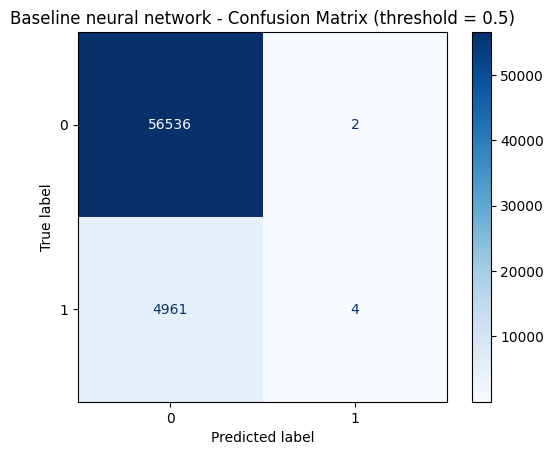

In [8]:
class BaselineNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


baseline_model, baseline_history, baseline_best_val_auc = train_network(
    BaselineNN(X_train_base_p.shape[1]),
    X_train_base_p, y_train,
    X_val_base_p, y_val,
    epochs=15, batch_size=512, learning_rate=0.001,
    weight_decay=0.0, patience=15  # baseline runs all epochs
)

baseline_test_prob = predict_probabilities(baseline_model, X_test_base_p)
baseline_results = evaluate_model(y_test, baseline_test_prob, model_name="Baseline neural network")


## 7. Improvement: feature engineering

These features describe affordability, age, employment history, household resources, and missingness. Ratios use a small denominator safeguard to avoid division by zero. The `DAYS_EMPLOYED = 365243` value is treated as a special missing/unknown value rather than real employment length.

In [9]:
def add_engineered_features(data):
    data = data.copy()

    # Clean unusual placeholder used for missing employment data.
    data["DAYS_EMPLOYED_ANOM"] = (data["DAYS_EMPLOYED"] == 365243).astype(int)
    data["DAYS_EMPLOYED"] = data["DAYS_EMPLOYED"].replace(365243, np.nan)

    # Make negative day counts easier for the model and for interpretation.
    data["AGE_YEARS"] = -data["DAYS_BIRTH"] / 365.25
    data["EMPLOYMENT_YEARS"] = -data["DAYS_EMPLOYED"] / 365.25

    income = data["AMT_INCOME_TOTAL"].clip(lower=1)
    credit = data["AMT_CREDIT"].clip(lower=1)
    family = data["CNT_FAM_MEMBERS"].fillna(1).clip(lower=1)

    data["CREDIT_TO_INCOME"] = data["AMT_CREDIT"] / income
    data["ANNUITY_TO_INCOME"] = data["AMT_ANNUITY"] / income
    data["GOODS_TO_CREDIT"] = data["AMT_GOODS_PRICE"] / credit
    data["INCOME_PER_FAMILY_MEMBER"] = data["AMT_INCOME_TOTAL"] / family
    data["CHILDREN_PER_FAMILY_MEMBER"] = data["CNT_CHILDREN"] / family
    data["EXT_SOURCE_MEAN"] = data[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
    data["EXT_SOURCE_STD"] = data[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].std(axis=1)
    data["MISSING_FEATURE_COUNT"] = data.isna().sum(axis=1)

    return data


X_improved = add_engineered_features(df.drop(columns=["TARGET", "SK_ID_CURR"]))

# Same indices/split proportions as the baseline for a fair comparison.
X_train_imp, X_test_imp, y_train_imp, y_test_imp = train_test_split(
    X_improved, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train_imp, X_val_imp, y_train_imp, y_val_imp = train_test_split(
    X_train_imp, y_train_imp, test_size=0.20, random_state=SEED, stratify=y_train_imp
)

assert y_train_imp.index.equals(y_train.index)
assert y_val_imp.index.equals(y_val.index)
assert y_test_imp.index.equals(y_test.index)

print("Engineered features added:", X_improved.shape[1] - X_base.shape[1])


Engineered features added: 11


## 8. Preprocess, train, and evaluate the improved model

Improved feature count after preprocessing: 255
Epoch 01 | loss: 0.2867 | validation ROC-AUC: 0.7404
Epoch 02 | loss: 0.2537 | validation ROC-AUC: 0.7388
Epoch 03 | loss: 0.2520 | validation ROC-AUC: 0.7455
Epoch 04 | loss: 0.2508 | validation ROC-AUC: 0.7444
Epoch 05 | loss: 0.2497 | validation ROC-AUC: 0.7476
Epoch 06 | loss: 0.2491 | validation ROC-AUC: 0.7462
Epoch 07 | loss: 0.2486 | validation ROC-AUC: 0.7421
Epoch 08 | loss: 0.2481 | validation ROC-AUC: 0.7442
Epoch 09 | loss: 0.2477 | validation ROC-AUC: 0.7469
Epoch 10 | loss: 0.2470 | validation ROC-AUC: 0.7469
Early stopping
Model        Feature-engineered improved neural network
ROC-AUC                                        0.751122
Accuracy                                       0.919272
Precision                                           0.0
Recall                                              0.0
F1                                                  0.0
dtype: object


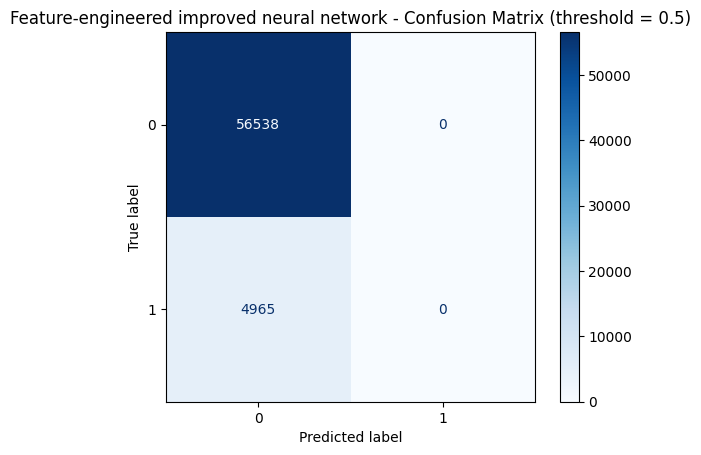

In [11]:
categorical_cols_imp = X_improved.select_dtypes(include=["object"]).columns.tolist()
numeric_cols_imp = X_improved.select_dtypes(exclude=["object"]).columns.tolist()

preprocessor_imp = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols_imp),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols_imp)
])

X_train_imp_p = preprocessor_imp.fit_transform(X_train_imp).astype(np.float32)
X_val_imp_p = preprocessor_imp.transform(X_val_imp).astype(np.float32)
X_test_imp_p = preprocessor_imp.transform(X_test_imp).astype(np.float32)

print("Improved feature count after preprocessing:", X_train_imp_p.shape[1])


class ImprovedNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


improved_model, improved_history, improved_best_val_auc = train_network(
    ImprovedNN(X_train_imp_p.shape[1]),
    X_train_imp_p, y_train_imp,
    X_val_imp_p, y_val_imp,
    epochs=30, batch_size=512, learning_rate=0.001,
    weight_decay=1e-4, patience=5
)

improved_test_prob = predict_probabilities(improved_model, X_test_imp_p)
improved_results = evaluate_model(y_test_imp, improved_test_prob, model_name="Feature-engineered improved neural network")


## 9. Compare the two versions

,ROC-AUC,Accuracy,Precision,Recall,F1
Model,,,,,
Baseline neural network,0.7470,0.9193,0.6667,0.0008,0.0016
Feature-engineered improved neural network,0.7511,0.9193,0.0000,0.0000,0.0000



Best validation ROC-AUC
Baseline: 0.7424
Improved: 0.7476


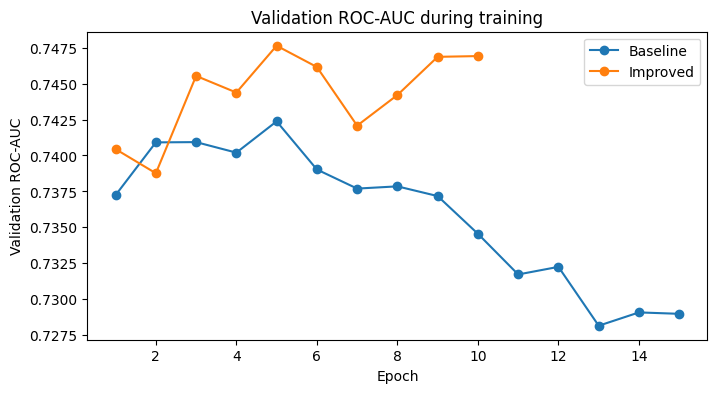

In [12]:
comparison = pd.DataFrame([baseline_results, improved_results]).set_index("Model")
display(comparison.style.format("{:.4f}"))

print("\nBest validation ROC-AUC")
print("Baseline:", round(baseline_best_val_auc, 4))
print("Improved:", round(improved_best_val_auc, 4))

plt.figure(figsize=(8, 4))
plt.plot(baseline_history["epoch"], baseline_history["val_auc"], marker="o", label="Baseline")
plt.plot(improved_history["epoch"], improved_history["val_auc"], marker="o", label="Improved")
plt.xlabel("Epoch")
plt.ylabel("Validation ROC-AUC")
plt.title("Validation ROC-AUC during training")
plt.legend()
plt.show()


## Baseline vs. Improved Model Results

The feature-engineered improved neural network achieved a test ROC-AUC of **0.7511**, compared with **0.7470** for the baseline neural network. This is an absolute increase of **0.0041 ROC-AUC points** (about **0.41 percentage points**), or roughly a **0.55% relative improvement** over the baseline.

The improved model also had a higher best validation ROC-AUC (**0.7476**) than the baseline (**0.7424**). This suggests that the added financial ratios, age and employment features, external-source summary features, and missing-value count provided a modest improvement in the model’s ability to rank applicants by repayment difficulty.

Accuracy stayed almost identical at about **91.93%** for both models. However, accuracy is not very informative for this dataset because only about 8% of applicants have repayment difficulty. At the default 0.50 classification threshold, both models predicted very few applicants as having repayment difficulty, which led to extremely low recall and F1 scores. For this reason, ROC-AUC is the more useful primary metric for comparing these models.